In [4]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

Image Shape: (28, 28)


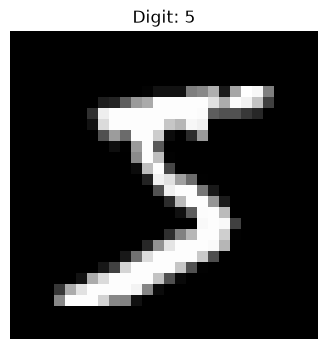

In [5]:
image = X_train[0]
label = y_train[0]

print("Image Shape:", image.shape)

plt.figure(figsize=(4,4))
plt.imshow(image, cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

In [6]:
#normalizing the pixel values

X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
print("Minimum pixel:", X_train.min())
print("Maximum pixel:", X_train.max())

Minimum pixel: 0.0
Maximum pixel: 1.0


In [14]:
def convolution(image, kernel, stride=1):

    img_height, img_width = image.shape
    kernel_height, kernel_width = kernel.shape

    output_height = (img_height - kernel_height) // stride + 1
    output_width = (img_width - kernel_width) // stride + 1

    output = np.zeros((output_height, output_width))

    # for i in range(output_height):
    #     for j in range(output_width):
    #         region = image[
    #             i*stride : i*stride + kernel_height,
    #             j*stride : j*stride + kernel_width
    #             ]

    #         output[i, j] = np.sum(region * kernel)

    # for(int i = 0; i < output.size(); i++){
    #     for (int j = 0; j < output.size(); j++){
    #         for(int k = 0; k < kernel.size(); k++){
    #             for(int l = 0; l < kernel.size(); l++){

    #                 int m = i * stride + k;
    #                 int n = j * stride + l;

    #                 output[i][j] += image[m][n] * kernel[k][l];
    #             }
    #         }
    #     }
    # }

    for i in range(output_height):
        for j in range(output_width):
            for k in range(kernel_height):
                for l in range(kernel_width):
                    m = i * stride + k
                    n = j * stride + l
                    output[i, j] += image[m, n] + kernel[k, l]

    return output

In [15]:
X = np.array([
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 16]
])

K = np.array([
    [1, 0],
    [0, 1]
])

result = convolution(X, K)
print(result)

[[16. 20. 24.]
 [32. 36. 40.]
 [48. 52. 56.]]
